<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="40"/>&nbsp;&nbsp;&nbsp;&nbsp;<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/c3s_logoline_pos.png" alt="Copernicus" height="28"/>

# La saison des pluies 2024 au Sénégal dans ERA5 🌧️
### Service Copernicus concernant le changement climatique · ERA5 · compte gratuit
*Réalisé pour SEWA (Strengthening Early Warnings for Africa), le renforcement des alertes précoces en Afrique*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/rain_era5_fr.ipynb)

La saison des pluies 2024 (juin à octobre) a-t-elle été plus humide qu'une année normale ? Ce notebook utilise les
**moyennes mensuelles d'ERA5**, la réanalyse Copernicus que l'ECMWF produit pour l'Union européenne, pour comparer
2024 à la moyenne 1991–2020, en pourcentage de la normale. Le fleuve Sénégal prend sa source dans les hauts plateaux
de Guinée et du Mali : la carte couvre donc tout son bassin.

**Ce qu'il vous faut :** un compte Google (pour utiliser Colab) et un compte Copernicus gratuit (étape ci-dessous). Tout tourne sur les ordinateurs de Google : les données y sont téléchargées, pas sur votre
téléphone ou votre ordinateur, donc une connexion lente ou mobile suffit.

| Données | Ce que ce notebook utilise | Licence |
|---|---|---|
| Moyennes mensuelles ERA5, environ 31 km | Précipitations totales, juin–octobre, 1991–2024 | licence Copernicus, gratuit |

**Outils :** [earthkit](https://earthkit.ecmwf.int), les outils Python libres et gratuits de l'ECMWF pour les données météo et climat.

*Cliquez sur **Exécution → Tout exécuter** (Runtime → Run all). Le data store met les demandes en file d'attente : l'étape 2 peut prendre quelques minutes.*

In [ ]:
# Installer les outils libres (Colab / nouvelle machine). Environ 1 minute.
%pip install -q "earthkit-data[cds]" earthkit-plots

## Votre clé Copernicus gratuite

Les données Copernicus sont libres et gratuites, mais les data stores demandent de s'inscrire une fois pour gérer la file d'attente :
1. Créez un compte sur [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (le même identifiant sert pour
   l'Atmosphere Data Store).
2. Ouvrez la [page du jeu de données](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-monthly-means?tab=download) sur le Climate Data Store et acceptez sa licence (en bas de l'onglet Download). Une seule fois suffit.
3. Copiez votre clé API depuis votre [page de profil](https://cds.climate.copernicus.eu/profile) et collez-la ci-dessous.

**Utilisez votre propre clé.** Chaque personne qui exécute ce notebook a besoin de son propre compte et de sa clé
Copernicus gratuits. La cellule suivante demande la clé dans un champ masqué et l'enregistre sur la machine qui exécute
le notebook (dans Colab, une machine temporaire effacée à la fermeture de l'onglet). La clé n'est jamais enregistrée dans
le notebook : ne la collez pas dans une cellule de code et ne partagez pas de notebook ou de capture d'écran qui la montre.
Sur votre ordinateur, si `~/.cdsapirc` / `~/.adsapirc` existent déjà, la cellule ne demande rien.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Clé API Copernicus : ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Clé Copernicus prête")

Clé Copernicus prête


In [3]:
import pyproj                     # à importer avant earthkit.data (évite un plantage à la fermeture)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np

JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
MOIS = ["janvier", "février", "mars", "avril", "mai", "juin", "juillet", "août", "septembre", "octobre",
        "novembre", "décembre"]
def jour(d): return f"{JOURS[d.weekday()]} {d.day} {MOIS[d.month - 1]}"     # dates en français
def date(d): return f"{d.day} {MOIS[d.month - 1]} {d.year}"

## 1 · Choisir la saison, l'année et la zone

In [4]:
AREA   = [18.0, -18.5, 9.0, -6.0]                     # nord, ouest, sud, est
YEAR   = 2024
MONTHS = ["06", "07", "08", "09", "10"]               # juin à octobre
DAYS   = {"06": 30, "07": 31, "08": 31, "09": 30, "10": 31}
CITIES = [("Dakar", 14.716, -17.467), ("Saint-Louis", 16.018, -16.489), ("Touba", 14.850, -15.883),
          ("Tambacounda", 13.771, -13.667), ("Ziguinchor", 12.583, -16.272), ("Kédougou", 12.557, -12.174)]

def label_cities(ax):
    for name, la, lo in CITIES:
        ax.scatter([lo], [la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10,
                   transform=ccrs.PlateCarree())
        ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Télécharger les pluies mensuelles ERA5, 1991–2020 et l'année choisie

In [5]:
era = ekd.from_source("cds", "reanalysis-era5-single-levels-monthly-means", {
    "product_type": "monthly_averaged_reanalysis", "variable": "total_precipitation",
    "year": [str(y) for y in range(1991, 2021)] + [str(YEAR)], "month": MONTHS, "time": "00:00",
    "area": AREA, "data_format": "grib"}).to_xarray()
tp = era[list(era.data_vars)[0]]                                   # mètres par jour, moyenne mensuelle
tdim = [d for d in tp.dims if d not in ("latitude", "longitude")][0]
t = tp[tdim].dt
mm = tp * 1000 * tp[tdim].dt.days_in_month                       # -> mm par mois
season = mm.groupby(t.year).sum(tdim)                             # mm de juin à octobre, chaque année
normal = season.sel(year=slice(1991, 2020)).mean("year")
this = season.sel(year=YEAR)
pct = 100 * this / normal
print(f"{YEAR} : {float(this.mean()):.0f} mm sur la zone, normale {float(normal.mean()):.0f} mm "
      f"({float(100 * this.mean() / normal.mean()):.0f} % de la normale)")
for n, la, lo in CITIES:
    print(f"  {n:12s} {float(this.sel(latitude=la, longitude=lo, method='nearest')):5.0f} mm, "
          f"{float(pct.sel(latitude=la, longitude=lo, method='nearest')):4.0f} % de la normale")

2024 : 916 mm sur la zone, normale 752 mm (122 % de la normale)
  Dakar          480 mm,  175 % de la normale
  Saint-Louis    101 mm,   70 % de la normale
  Touba          388 mm,  103 % de la normale
  Tambacounda    634 mm,  109 % de la normale
  Ziguinchor    1445 mm,  122 % de la normale
  Kédougou       849 mm,  104 % de la normale


## 3 · La cartographier

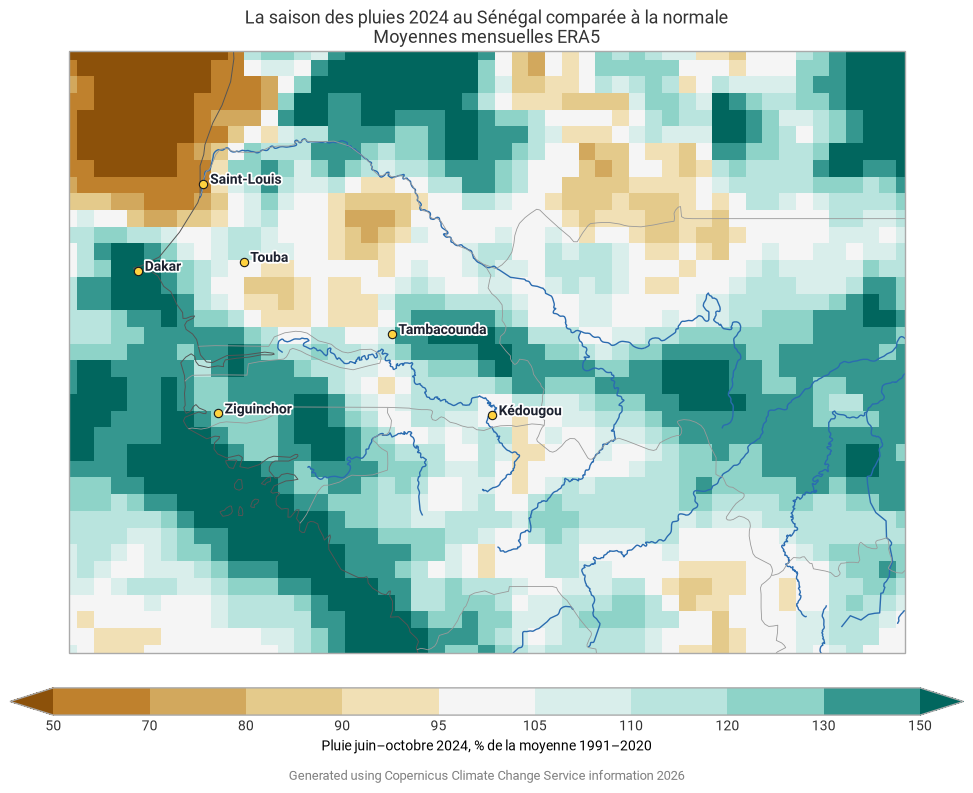

In [6]:
colors = ["#8c510a", "#bf812d", "#dfc27d", "#f6e8c3", "#f5f5f5", "#c7eae5", "#80cdc1", "#35978f", "#01665e"]
style = ekp.styles.Style(levels=[50, 70, 80, 90, 95, 105, 110, 120, 130, 150], colors=colors, extend="both")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(12, 7.5))
chart.pcolormesh(pct, style=style)
chart.coastlines(linewidth=0.7); chart.borders(linewidth=0.6)
chart.ax.add_feature(__import__("cartopy").feature.RIVERS, edgecolor="#2b6cb0", linewidth=1.0)
label_cities(chart.ax)
chart.legend(label=f"Pluie juin–octobre {YEAR}, % de la moyenne 1991–2020")
chart.title(f"La saison des pluies {YEAR} au Sénégal comparée à la normale\nMoyennes mensuelles ERA5", fontsize=13)
chart.attribution("Generated using Copernicus Climate Change Service information 2026")
chart.save("rain_era5_fr.png")
chart.show()

## 4 · À vous de jouer 🌍

- **Une autre année :** `YEAR = 2020` ou toute année depuis 1940.
- **Seulement les mois les plus pluvieux :** `MONTHS = ["08", "09"]`.
- **Plus chaud ou plus frais que la normale :** `"2m_temperature"` (kelvins) et `this - normal` au lieu d'un pourcentage.

### Données et licence
Les données Copernicus sont libres et gratuites sous licence Copernicus (CC-BY 4.0). Mention :
*Generated using Copernicus Climate Change Service information 2026.* L'ECMWF opère le service Copernicus de surveillance de l'atmosphère (CAMS) et le
service Copernicus concernant le changement climatique (C3S) pour l'Union européenne.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)